# PRAKTIKUM DATA MINING
## Tugas 3 — Perbandingan Apriori vs FP-Growth pada Ambang Lebih Rendah

- **Mata Kuliah**: Praktikum Data Mining
- **Topik**: Komparasi Efisiensi Komputasi Algoritma Frequent Pattern Mining (Candidate Generation vs Pattern Growth)
- **Dataset**: 60 Transaksi Toko Kelontong (`transactions_arm_praktikum.csv`)
- **Referensi Modul**: *Modul Praktikum Data Mining — Bagian 5.3 (Tugas 3)*


---
## Persiapan Data & Pustaka
Memuat pustaka yang dibutuhkan, membaca dataset 60 transaksi, dan melakukan transformasi matriks one-hot agar notebook dapat dieksekusi secara mandiri (*self-contained*).


In [1]:
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth

# Membaca dataset
df_raw = pd.read_csv('transactions_arm_praktikum.csv')
transactions = [x.split(', ') for x in df_raw['Items'].dropna()]

# Encoding One-Hot
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df = pd.DataFrame(te_ary, columns=te.columns_)

print(f'Dataset 60 transaksi berhasil dimuat dan di-encode menjadi matriks {df.shape}.')


Dataset 60 transaksi berhasil dimuat dan di-encode menjadi matriks (60, 12).


---
# TUGAS 3 — Perbandingan Apriori vs FP-Growth pada Ambang Lebih Rendah

### 3.1 & 3.2 Ulangi Eksperimen pada min_support = 0.05
Menguji efisiensi komputasi kedua algoritma ketika ruang pencarian kandidat meningkat secara signifikan.


In [2]:
# Benchmark berulang untuk kestabilan pengukuran
times_ap_low = []
times_fp_low = []

for _ in range(20):
    t0 = time.perf_counter()
    fi_ap_low = apriori(df, min_support=0.05, use_colnames=True)
    times_ap_low.append((time.perf_counter() - t0) * 1000)
    
    t0 = time.perf_counter()
    fi_fp_low = fpgrowth(df, min_support=0.05, use_colnames=True)
    times_fp_low.append((time.perf_counter() - t0) * 1000)

avg_ap_low = np.mean(times_ap_low)
avg_fp_low = np.mean(times_fp_low)

set_ap_low = set(frozenset(s) for s in fi_ap_low['itemsets'])
set_fp_low = set(frozenset(s) for s in fi_fp_low['itemsets'])

print(f"min_support = 0.05:")
print(f"- Jumlah Frequent Itemsets Apriori  : {len(fi_ap_low)}")
print(f"- Jumlah Frequent Itemsets FP-Growth: {len(fi_fp_low)}")
print(f"- Itemset Identik?                  : {set_ap_low == set_fp_low}")
print(f"- Waktu Rata-rata Apriori          : {avg_ap_low:.2f} ms")
print(f"- Waktu Rata-rata FP-Growth        : {avg_fp_low:.2f} ms")
print(f"- Kecepatan Relatif FP-Growth      : {avg_ap_low / avg_fp_low:.2f}x lebih cepat")


min_support = 0.05:
- Jumlah Frequent Itemsets Apriori  : 42
- Jumlah Frequent Itemsets FP-Growth: 42
- Itemset Identik?                  : True
- Waktu Rata-rata Apriori          : 1.44 ms
- Waktu Rata-rata FP-Growth        : 0.93 ms
- Kecepatan Relatif FP-Growth      : 1.54x lebih cepat


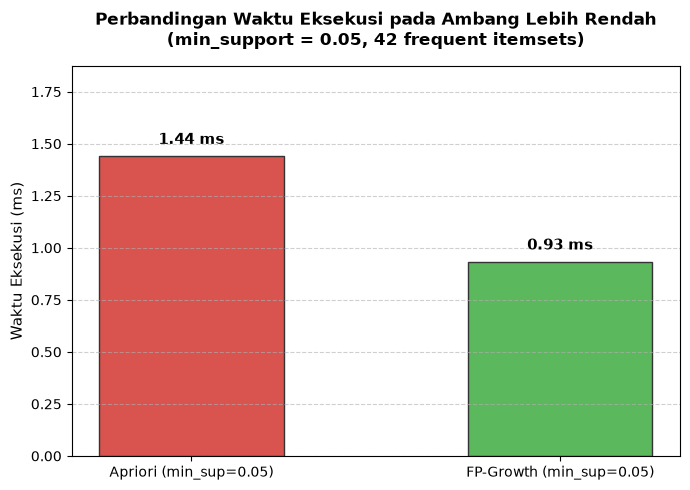

In [3]:
# Visualisasi Perbandingan Waktu Eksekusi pada min_support = 0.05
plt.figure(figsize=(7, 5))
bars = plt.bar(['Apriori (min_sup=0.05)', 'FP-Growth (min_sup=0.05)'], [avg_ap_low, avg_fp_low], color=['#d9534f', '#5cb85c'], width=0.5, edgecolor='#333333')
plt.title('Perbandingan Waktu Eksekusi pada Ambang Lebih Rendah\n(min_support = 0.05, 42 frequent itemsets)', fontsize=12, fontweight='bold', pad=15)
plt.ylabel('Waktu Eksekusi (ms)', fontsize=11)
plt.ylim(0, max(avg_ap_low, avg_fp_low) * 1.3)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.04, f'{yval:.2f} ms', ha='center', va='bottom', fontsize=11, fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


### 3.3 Analisis Performa Teoritis Apriori vs FP-Growth
1. **Analisis Selisih Waktu**:
   - Pada `min_support = 0.15`, itemset yang ditemukan berjumlah 17. Apriori dan FP-Growth mengeksekusi dengan selisih waktu yang relatif kecil.
   - Pada `min_support = 0.05`, jumlah frequent itemset melonjak drastis menjadi **42 itemset**. Waktu eksekusi Apriori meningkat karena harus membangkitkan kandidat $k$-itemset dan memindai database berulang kali (level-wise scan). Sebaliknya, FP-Growth tetap stabil dan cepat.
2. **Penyebab Teoritis**:
   - **Apriori**: Melakukan pembentukan kandidat eksplisit ($C_k$) dan scanning database sebanyak $k$ kali (setara kedalaman itemset terbesar). Jika ambang batas diturunkan, jumlah kombinasi kandidat combinatorial meledak secara eksponensial ($O(2^n)$).
   - **FP-Growth**: Mengadopsi struktur data pohon padat (**FP-Tree**) yang hanya memerlukan 2 kali pemindaian database utuh. Penambangan frequent itemset dilakukan secara rekursif melalui *conditional pattern bases* tanpa membangkitkan calon kandidat eksplisit (*candidate generation-free*).
